# Phase 5B — processor figures and zero-shot validation baseline

**Goal:** document the Whisper audio-to-feature conversion, verify the code-point CER scorer, run a small validation preflight, and then (only when enabled) score all 732 frozen validation clips with the pinned IPA-Whisper Base checkpoint.

This notebook is designed for **Kaggle with a GPU**. It expects two attached private datasets:

1. **Phase 5A validation bundle** — the extracted folder containing `bundle_record.json`, `validation_manifest.csv`, `SHA256SUMS.txt`, and `audio/`.
2. **Phase 4 training-smoke bundle** — the extracted folder containing `bundle_record.json`, `smoke_manifest.csv`, and `audio/`. These 12 training-only examples are used only for processor plots, never for validation scoring.

In Kaggle, use **Add Input** to attach both datasets. Set **Accelerator = GPU** and enable **Internet** so Kaggle can fetch the pinned public Hugging Face checkpoint. The notebook discovers nested Kaggle paths automatically; do not type a `/kaggle/input/datasets/...` path and do not unzip or prepend `audio/` manually.

> **Test protection:** no test audio is needed or used. The full validation run is controlled by `RUN_FULL_VALIDATION = False` below. Review the preflight output first; change it to `True` only when ready to run all 732 validation clips. Keep generated predictions and exports private because they contain references and hypotheses.

**Pinned experiment:** `neurlang/ipa-whisper-base` revision `949f7c4e4ee374b5202bc5886f6e4552e5ae2371`; FP32 inference; batch size 1; greedy decoding; NFD + outer trim + repeated ordinary U+0020-space collapse; preserve all IPA marks, punctuation, and spaces. Corpus CER is the sum of per-clip character edits divided by the total number of reference code points. Failed/empty outputs remain in the denominator.


## 1. Inspect Kaggle inputs

Kaggle mounts datasets under `/kaggle/input`; attaching a dataset through **Add Input** is sufficient. This inventory helps diagnose a missing or wrongly attached bundle.

In [1]:
import subprocess
import sys

# Pin the Hugging Face packages used for the Phase 4-compatible baseline.
# This does not install or change PyTorch/CUDA.
packages = [
    "transformers==4.57.1",
    "tokenizers==0.22.2",
    "huggingface-hub==0.36.2",
    "safetensors==0.8.0",
]

subprocess.run(
    [
        sys.executable, "-m", "pip", "install",
        "--quiet", "--no-cache-dir", "--no-deps",
        *packages,
    ],
    check=True,
)

print("Pinned packages installed. Restart the Kaggle session before continuing.")

Pinned packages installed. Restart the Kaggle session before continuing.


In [2]:
import os
from pathlib import Path
import kagglehub

# Kaggle's Add Input panel is the recommended way to attach the two private bundles.
# If you prefer kagglehub, add authorized owner/dataset-slug strings here; leave empty when using Add Input.
KAGGLEHUB_DATASET_SLUGS = []
for dataset_slug in KAGGLEHUB_DATASET_SLUGS:
    downloaded_path = kagglehub.dataset_download(dataset_slug)
    print(f"kagglehub downloaded {dataset_slug} to {downloaded_path}")

INPUT_ROOT = Path("/kaggle/input")
if not INPUT_ROOT.is_dir():
    raise FileNotFoundError("This notebook expects Kaggle's /kaggle/input directory.")

# This mirrors Kaggle's starter inventory cell and prints the mounted file paths.
visible_file_count = 0
for dirname, _, filenames in os.walk(INPUT_ROOT):
    for filename in filenames:
        print(os.path.join(dirname, filename))
        visible_file_count += 1
print(f"\nTotal mounted files: {visible_file_count}")
print("Attach the Phase 5A validation dataset and Phase 4 training-smoke dataset with Add Input if either bundle is missing.")


/kaggle/input/datasets/kanchanpotdar/phase5-validation-bundle/README.md
/kaggle/input/datasets/kanchanpotdar/phase5-validation-bundle/SHA256SUMS.txt
/kaggle/input/datasets/kanchanpotdar/phase5-validation-bundle/baseline_protocol.json
/kaggle/input/datasets/kanchanpotdar/phase5-validation-bundle/bundle_record.json
/kaggle/input/datasets/kanchanpotdar/phase5-validation-bundle/generation_config.json
/kaggle/input/datasets/kanchanpotdar/phase5-validation-bundle/validation_manifest.csv
/kaggle/input/datasets/kanchanpotdar/phase5-validation-bundle/audio/A_000052.wav
/kaggle/input/datasets/kanchanpotdar/phase5-validation-bundle/audio/A_000053.wav
/kaggle/input/datasets/kanchanpotdar/phase5-validation-bundle/audio/A_000055.wav
/kaggle/input/datasets/kanchanpotdar/phase5-validation-bundle/audio/A_000056.wav
/kaggle/input/datasets/kanchanpotdar/phase5-validation-bundle/audio/A_000067.wav
/kaggle/input/datasets/kanchanpotdar/phase5-validation-bundle/audio/A_000068.wav
/kaggle/input/datasets/kanch

## 2. Check the runtime

This cell reports the actual Kaggle Python, PyTorch, Transformers, CUDA, and GPU versions. The notebook does not run `pip install`, avoiding changes to Kaggle's active package environment. Transformers must match the Phase 4 stack for this declared run.

In [3]:
import copy
import hashlib
import random
import json
import math
import os
import platform
import re
import time
import unicodedata
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
import torch
import transformers
import tokenizers
import huggingface_hub
from IPython.display import display
from transformers import GenerationConfig, WhisperForConditionalGeneration, WhisperProcessor

EXPECTED_TRANSFORMERS = "4.57.1"
print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Tokenizers:", tokenizers.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)
print("NumPy:", np.__version__)
print("SoundFile:", sf.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    raise RuntimeError("No GPU is active. In Kaggle, open Notebook Settings → Accelerator → GPU, save, then restart and rerun from the top.")
if transformers.__version__ != EXPECTED_TRANSFORMERS:
    raise RuntimeError(
        f"This protocol expects Transformers {EXPECTED_TRANSFORMERS}, but Kaggle has {transformers.__version__}. "
        "Use the Phase 4-compatible Kaggle environment before continuing; do not continue with a different generation stack."
    )
DEVICE = torch.device("cuda:0")
SEED = 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
print("Seed:", SEED)


Python: 3.13.15
PyTorch: 2.11.0+cu128
Transformers: 4.57.1
Tokenizers: 0.22.2
Hugging Face Hub: 0.36.2
NumPy: 2.1.3
SoundFile: 0.14.0
CUDA available: True
GPU: Tesla T4
Seed: 0


## 3. Find both bundles by marker file

Kaggle may assign different owner/dataset directory names. We identify the folders by their bundle metadata, then always resolve each CSV audio path relative to its own bundle root. That avoids the earlier `audio/audio/...` path error.

In [4]:
def read_json(path):
    return json.loads(path.read_text(encoding="utf-8"))

bundle_markers = []
for marker in INPUT_ROOT.rglob("bundle_record.json"):
    try:
        record = read_json(marker)
    except Exception as exc:
        print(f"Skipping unreadable marker {marker}: {exc}")
        continue
    bundle_markers.append((marker.parent.resolve(), record))

validation_matches = [
    (path, record) for path, record in bundle_markers
    if record.get("bundle_type") == "phase5_validation_baseline"
    and record.get("evaluation_partition") == "validation"
]
smoke_matches = [
    (path, record) for path, record in bundle_markers
    if "Phase 4" in str(record.get("purpose", ""))
    and (path / "smoke_manifest.csv").is_file()
]
if len(validation_matches) != 1 or len(smoke_matches) != 1:
    summary = [(str(path), rec.get("bundle_type"), rec.get("purpose")) for path, rec in bundle_markers]
    raise FileNotFoundError(
        "Expected exactly one extracted Phase 5A validation bundle and one Phase 4 training-smoke bundle. "
        f"Found validation={len(validation_matches)}, smoke={len(smoke_matches)}. "
        f"Detected bundle markers: {summary}. Attach both datasets using Kaggle Add Input."
    )

VALIDATION_ROOT, VALIDATION_RECORD = validation_matches[0]
SMOKE_ROOT, SMOKE_RECORD = smoke_matches[0]
print("Phase 5A validation bundle:", VALIDATION_ROOT)
print("Phase 4 training-smoke bundle:", SMOKE_ROOT)
print("Validation record:", {k: VALIDATION_RECORD.get(k) for k in ("bundle_type", "split_version", "clips", "hours", "components")})
print("Smoke record:", {k: SMOKE_RECORD.get(k) for k in ("smoke_audio_count", "smoke_audio_scope", "contains_validation_or_test_audio")})


Phase 5A validation bundle: /kaggle/input/datasets/kanchanpotdar/phase5-validation-bundle
Phase 4 training-smoke bundle: /kaggle/input/datasets/kanchanpotdar/phase4-smoke-bundle
Validation record: {'bundle_type': 'phase5_validation_baseline', 'split_version': 'phase3_5b_v1', 'clips': 732, 'hours': 1.8818083506944443, 'components': 16}
Smoke record: {'smoke_audio_count': 12, 'smoke_audio_scope': 'training only; one clip per component', 'contains_validation_or_test_audio': False}


## 4. Verify bundle hashes and validation manifest

This checks every Phase 5A payload checksum, including all WAV bytes, before model inference. It also verifies the manifest hash, frozen-split identity, sample count, references, and relative audio paths. It does not read any test data.

In [5]:
EXPECTED_VALIDATION_MANIFEST_SHA256 = "9ff2622420f7e662da82371dbfae9e941c2ead9bcb7e0a47f4e6fd5639e1e3cd"
EXPECTED_FROZEN_ALL_SHA256 = "77673030d6d7a4a864ef98c869eb9acf2295e80029862ca8a68e0489527903ac"
EXPECTED_VALIDATION_CLIPS = 732
EXPECTED_REFERENCE_CODEPOINTS = 64137


def sha256_file(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


def safe_bundle_path(bundle_root, relative_path):
    root = Path(bundle_root).resolve()
    candidate = (root / str(relative_path)).resolve()
    try:
        candidate.relative_to(root)
    except ValueError as exc:
        raise ValueError(f"Bundle path escapes its root: {relative_path}") from exc
    return candidate


def verify_sha256_list(bundle_root):
    sums_path = Path(bundle_root) / "SHA256SUMS.txt"
    if not sums_path.is_file():
        raise FileNotFoundError(f"Checksum list is missing: {sums_path}")
    expected = {}
    for line_number, line in enumerate(sums_path.read_text(encoding="utf-8").splitlines(), start=1):
        if not line.strip():
            continue
        try:
            expected_hash, relative_path = line.split("  ", 1)
        except ValueError as exc:
            raise ValueError(f"Malformed SHA256SUMS.txt line {line_number}.") from exc
        if relative_path in expected:
            raise ValueError(f"Duplicate checksum entry: {relative_path}")
        expected[relative_path] = expected_hash
    failures = []
    for relative_path, expected_hash in expected.items():
        file_path = safe_bundle_path(bundle_root, relative_path)
        if not file_path.is_file():
            failures.append(f"missing: {relative_path}")
            continue
        actual_hash = sha256_file(file_path)
        if actual_hash != expected_hash:
            failures.append(f"hash mismatch: {relative_path}")
    if failures:
        raise RuntimeError("Phase 5A checksum verification failed: " + "; ".join(failures[:20]))
    return len(expected)


if VALIDATION_RECORD.get("contains_train_audio") is not False or VALIDATION_RECORD.get("contains_test_audio") is not False:
    raise ValueError("The Phase 5A bundle record does not guarantee validation-only audio.")
if VALIDATION_RECORD.get("frozen_validation_manifest_sha256") != EXPECTED_VALIDATION_MANIFEST_SHA256:
    raise ValueError("This is not the accepted frozen Phase 3.5B validation manifest.")
if VALIDATION_RECORD.get("frozen_all_manifest_sha256") != EXPECTED_FROZEN_ALL_SHA256:
    raise ValueError("The frozen-all manifest hash differs from the accepted split.")
if SMOKE_RECORD.get("contains_validation_or_test_audio") is not False:
    raise ValueError("The Phase 4 smoke bundle must be training-only.")

payload_count = verify_sha256_list(VALIDATION_ROOT)
if payload_count != 737:
    raise ValueError(f"Expected 737 Phase 5A payload hashes; found {payload_count}.")
manifest_path = VALIDATION_ROOT / "validation_manifest.csv"
manifest_hash = sha256_file(manifest_path)
if manifest_hash != VALIDATION_RECORD.get("manifest_sha256"):
    raise ValueError("validation_manifest.csv does not match bundle_record.json.")

validation = pd.read_csv(manifest_path, encoding="utf-8", keep_default_na=False)
required_columns = {
    "sample_id", "split", "component_id", "audio_file", "reference_raw", "reference",
    "reference_codepoints_nfd", "duration_seconds", "sample_rate", "channels", "frames", "audio_sha256"
}
missing_columns = sorted(required_columns - set(validation.columns))
if missing_columns:
    raise ValueError(f"Validation manifest is missing columns: {missing_columns}")
if len(validation) != EXPECTED_VALIDATION_CLIPS or validation["sample_id"].duplicated().any():
    raise ValueError("Expected exactly 732 unique frozen validation rows.")
if set(validation["split"]) != {"validation"}:
    raise ValueError("A non-validation row was found in the Phase 5A manifest.")
if validation["reference"].eq("").any() or validation["reference"].isna().any():
    raise ValueError("A validation reference is empty; stop and inspect the private bundle.")
if validation["sample_rate"].astype(int).ne(16000).any() or validation["channels"].astype(int).ne(1).any():
    raise ValueError("Expected 16 kHz mono validation WAVs.")
if validation["duration_seconds"].astype(float).le(0).any() or validation["duration_seconds"].astype(float).ge(30).any():
    raise ValueError("A validation duration is outside the frozen 0–30 second Whisper scope.")
normalized_references = validation["reference"].map(
    lambda value: re.sub(r" {2,}", " ", unicodedata.normalize("NFD", str(value)).strip())
)
if not normalized_references.equals(validation["reference"]):
    raise ValueError("A packaged reference is not in the approved NFD/trim/space-normalized form.")
per_row_reference_lengths = normalized_references.map(len).astype(int)
if not per_row_reference_lengths.equals(validation["reference_codepoints_nfd"].astype(int)):
    raise ValueError("A per-row normalized reference length does not match its code-point count.")
if int(validation["reference_codepoints_nfd"].astype(int).sum()) != EXPECTED_REFERENCE_CODEPOINTS:
    raise ValueError("The reference code-point denominator differs from the Phase 5A verified total.")

# All file paths are already relative to the directory containing bundle_record.json.
# In particular, audio/A_....wav must not be joined to another /audio directory.
for row in validation.itertuples(index=False):
    audio_path = safe_bundle_path(VALIDATION_ROOT, row.audio_file)
    if not audio_path.is_file():
        raise FileNotFoundError(f"Validation WAV is missing: {row.audio_file}")

smoke_path = SMOKE_ROOT / "smoke_manifest.csv"
smoke = pd.read_csv(smoke_path, encoding="utf-8", keep_default_na=False)
if len(smoke) != 12 or smoke["sample_id"].duplicated().any():
    raise ValueError("Expected exactly 12 unique training-only Phase 4 smoke clips.")
for row in smoke.itertuples(index=False):
    audio_path = safe_bundle_path(SMOKE_ROOT, row.audio_file)
    if not audio_path.is_file():
        raise FileNotFoundError(f"Training-smoke WAV is missing: {row.audio_file}")
    if sha256_file(audio_path) != row.audio_sha256:
        raise ValueError(f"Training-smoke WAV hash mismatch for {row.sample_id}.")

print(f"Phase 5A checks passed: {payload_count} hashes; {len(validation)} validation rows; {len(smoke)} training-smoke rows.")
print(f"Frozen validation hours: {validation.duration_seconds.astype(float).sum() / 3600:.6f}")
print(f"NFD reference code points including spaces: {EXPECTED_REFERENCE_CODEPOINTS:,}")
print("Validation audio paths resolve from bundle root; no audio/audio path is constructed.")


Phase 5A checks passed: 737 hashes; 732 validation rows; 12 training-smoke rows.
Frozen validation hours: 1.881808
NFD reference code points including spaces: 64,137
Validation audio paths resolve from bundle root; no audio/audio path is constructed.


## 5. Define and verify the CER policy

CER is calculated over Unicode code points **after** NFD normalization, outer trimming, and collapsing repeated ordinary spaces. Spaces and all IPA marks remain. The scorer computes each clip separately, then adds substitutions, deletions, and insertions across clips; it never averages clip CERs or joins clips together.

## CER policy and formula

We evaluate the model by comparing each predicted transcription with its reference **one clip at a time**.

Before scoring both reference and prediction, we apply the same minimal text normalization:

- Convert Unicode text to **NFD** form.
- Remove whitespace from the start and end.
- Collapse repeated ordinary spaces (`U+0020`) into one space.
- Keep spaces, punctuation, IPA symbols, and all marks, including tone and dental marks.

For each clip, the scorer counts:

- **S — substitutions:** reference characters replaced by different predicted characters.
- **D — deletions:** reference characters missing from the prediction.
- **I — insertions:** extra predicted characters.

The primary result is **corpus-level Unicode code-point Character Error Rate (CER)**:

\[
\mathrm{CER}
=
\frac{\sum_{k=1}^{N}(S_k + D_k + I_k)}
     {\sum_{k=1}^{N} R_k}
\]

where \(N\) is the number of evaluated clips and \(R_k\) is the number of normalized reference code points in clip \(k\).

We add the edit counts across clips and divide by the total number of reference code points. We **do not average per-clip CERs** or join clips together before scoring.

An empty prediction is retained: every reference code point in that clip counts as a deletion. Decode failures are also retained and reported; their empty outputs count as deletions. Repetitions, replacement characters (`�`), and outputs that reach the generation-length limit are kept and flagged for review. CER can exceed 100% when insertions outnumber reference characters.

CER measures character-level transcription difference under this policy. It does not by itself establish that a transcript is linguistically correct or that the model captures Nyishi tone.

In [6]:
def normalize_reference_or_hypothesis(text):
    text = unicodedata.normalize("NFD", str(text))
    text = text.strip()
    return re.sub(r" {2,}", " ", text)


def edit_counts(reference, hypothesis):
    """Return one optimal code-point edit decomposition (S, D, I)."""
    ref = list(reference)
    hyp = list(hypothesis)
    rows, cols = len(ref) + 1, len(hyp) + 1
    distance = [[0] * cols for _ in range(rows)]
    for i in range(rows):
        distance[i][0] = i
    for j in range(cols):
        distance[0][j] = j
    for i in range(1, rows):
        for j in range(1, cols):
            substitution_cost = 0 if ref[i - 1] == hyp[j - 1] else 1
            distance[i][j] = min(
                distance[i - 1][j] + 1,
                distance[i][j - 1] + 1,
                distance[i - 1][j - 1] + substitution_cost,
            )
    substitutions = deletions = insertions = 0
    i, j = len(ref), len(hyp)
    while i > 0 or j > 0:
        if i > 0 and j > 0 and ref[i - 1] == hyp[j - 1] and distance[i][j] == distance[i - 1][j - 1]:
            i -= 1
            j -= 1
        elif i > 0 and j > 0 and distance[i][j] == distance[i - 1][j - 1] + 1:
            substitutions += 1
            i -= 1
            j -= 1
        elif i > 0 and distance[i][j] == distance[i - 1][j] + 1:
            deletions += 1
            i -= 1
        elif j > 0 and distance[i][j] == distance[i][j - 1] + 1:
            insertions += 1
            j -= 1
        else:
            raise RuntimeError("Could not backtrack the character edit-distance matrix.")
    return substitutions, deletions, insertions


def score_text_pair(reference, hypothesis):
    ref = normalize_reference_or_hypothesis(reference)
    hyp = normalize_reference_or_hypothesis(hypothesis)
    s, d, i = edit_counts(ref, hyp)
    return {"reference": ref, "hypothesis": hyp, "S": s, "D": d, "I": i, "reference_codepoints": len(ref)}


# Small deterministic checks for exact match, substitution, deletion, insertion,
# combining marks, ordinary-space policy, and the empty-output rule.
assert score_text_pair("abc", "abc")["S"] == 0
assert score_text_pair("abc", "axc")["S"] == 1
assert score_text_pair("abc", "ac")["D"] == 1
assert score_text_pair("ac", "abc")["I"] == 1
assert score_text_pair("ã", "a\u0303")["S"] == 0
assert score_text_pair("a  b", "a b")["S"] == score_text_pair("a  b", "a b")["D"] == score_text_pair("a  b", "a b")["I"] == 0
assert score_text_pair("a b", "ab")["D"] == 1  # Spaces are part of CER.
assert score_text_pair("abc", "")["D"] == 3  # Empty predictions remain deletions.
assert normalize_reference_or_hypothesis("  a   b  ") == "a b"
print("CER self-checks passed. IPA marks are not stripped; only NFD and repeated ordinary spaces are normalized.")


CER self-checks passed. IPA marks are not stripped; only NFD and repeated ordinary spaces are normalized.


## 6. Load the pinned processor and plot the actual log-Mel features

The two plots use selected **training-only** Phase 4 smoke clips. They visualize the exact FP32 tensor returned by the pinned Whisper processor, its time and Mel-band axes, and the original-audio/padded region. Feature colors are scaled log-Mel feature values, **not calibrated dB**. These illustrations are separate from validation scoring.

In [7]:
MODEL_ID = "neurlang/ipa-whisper-base"
MODEL_REVISION = "949f7c4e4ee374b5202bc5886f6e4552e5ae2371"
SAMPLE_RATE = 16000

print("Loading pinned processor; Kaggle Internet must be enabled for the first download.")
processor = WhisperProcessor.from_pretrained(MODEL_ID, revision=MODEL_REVISION)
feature_extractor = processor.feature_extractor
print("Processor sampling rate:", feature_extractor.sampling_rate)
print("Mel bins:", feature_extractor.feature_size)
print("FFT size:", feature_extractor.n_fft)
print("Hop length:", feature_extractor.hop_length)
print("Maximum samples:", feature_extractor.n_samples)
if (feature_extractor.sampling_rate, feature_extractor.feature_size, feature_extractor.n_fft, feature_extractor.hop_length, feature_extractor.n_samples) != (16000, 80, 400, 160, 480000):
    raise ValueError("Processor feature settings differ from the verified Phase 4 Whisper setup.")


Loading pinned processor; Kaggle Internet must be enabled for the first download.


preprocessor_config.json:   0%|          | 0.00/356 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

normalizer.json: 0.00B [00:00, ?B/s]

added_tokens.json: 0.00B [00:00, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

Processor sampling rate: 16000
Mel bins: 80
FFT size: 400
Hop length: 160
Maximum samples: 480000


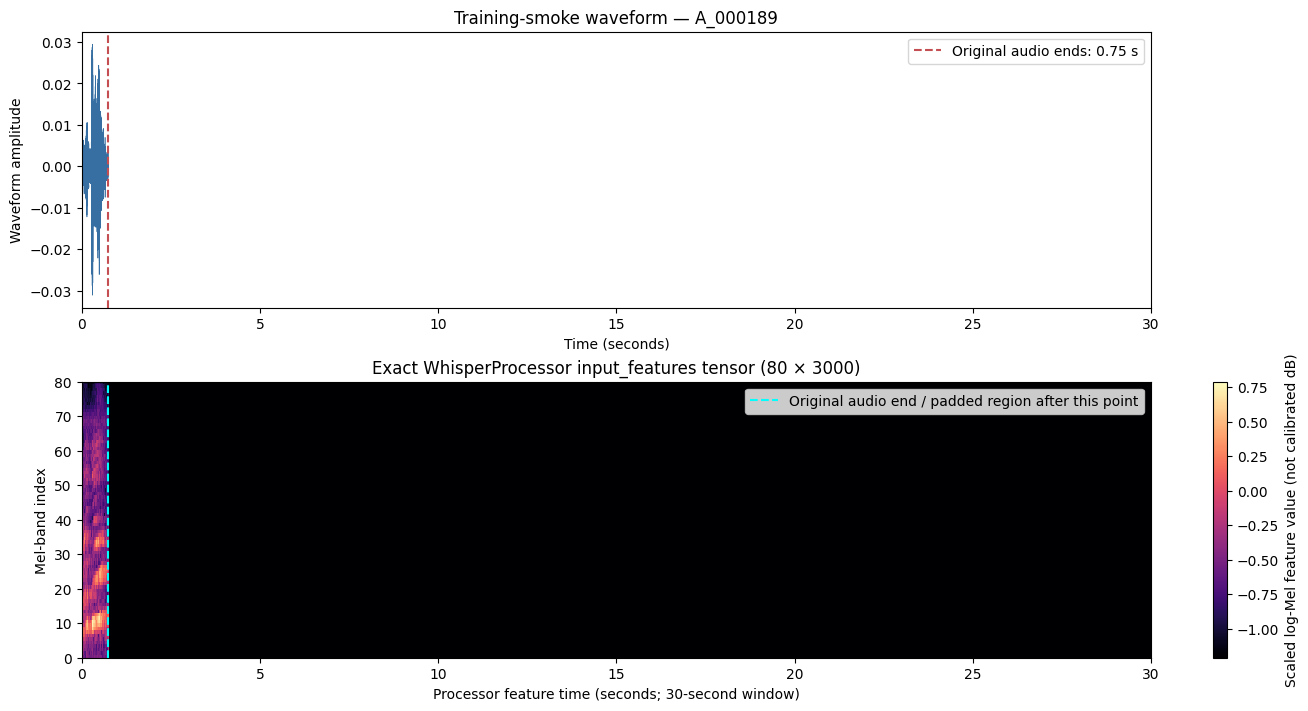

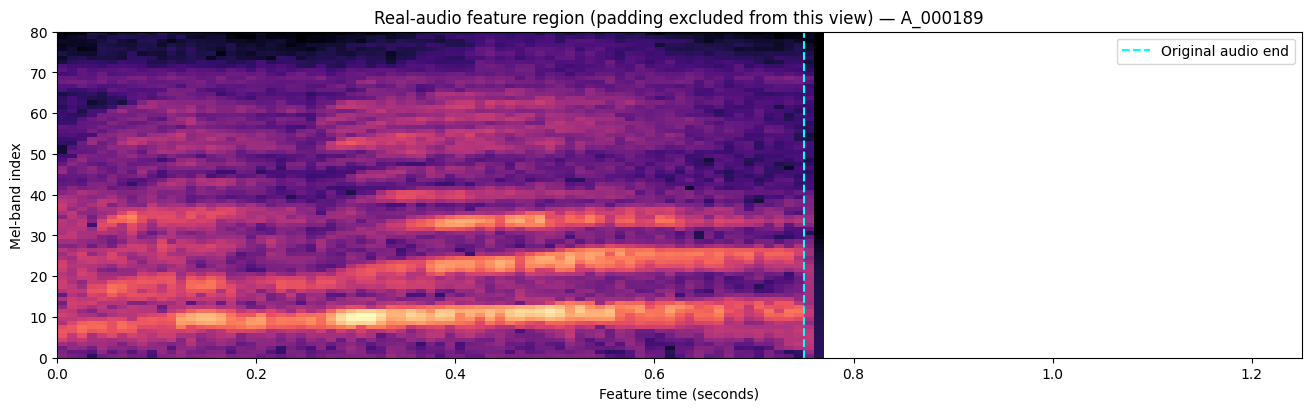

A_000189: 0.750s, sr=16000, feature shape=(1, 80, 3000), dtype=torch.float32, finite=True


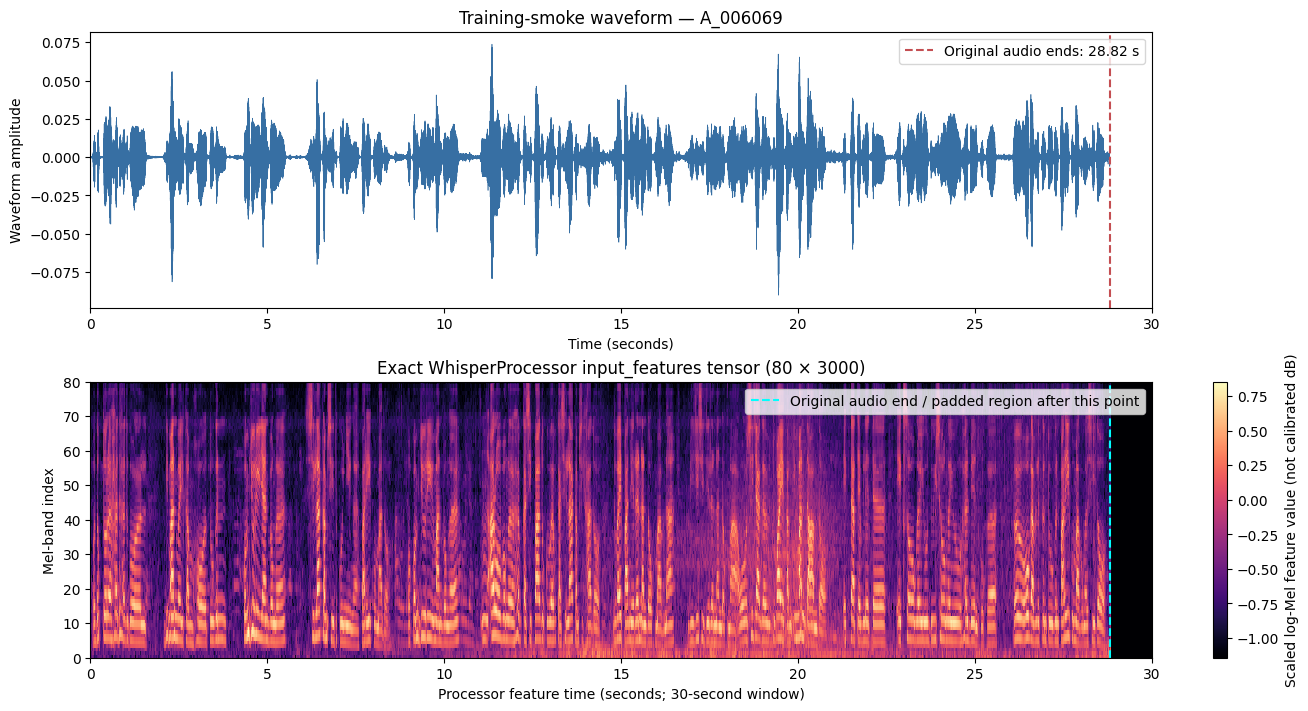

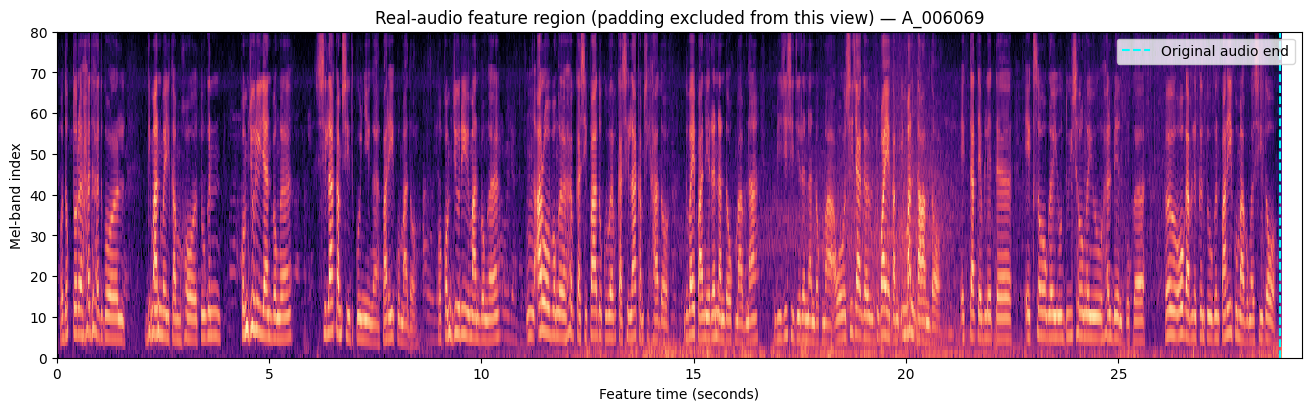

A_006069: 28.820s, sr=16000, feature shape=(1, 80, 3000), dtype=torch.float32, finite=True


In [8]:
def read_bundle_audio(bundle_root, row):
    audio_path = safe_bundle_path(bundle_root, row.audio_file)
    waveform, sample_rate = sf.read(audio_path, dtype="float32", always_2d=True)
    if sample_rate != SAMPLE_RATE or waveform.shape[1] != 1 or waveform.shape[0] == 0:
        raise ValueError(
            f"Unexpected audio format for {row.sample_id}: sample_rate={sample_rate}, shape={waveform.shape}"
        )
    expected_duration = float(row.duration_seconds)
    actual_duration = len(waveform) / sample_rate
    if abs(actual_duration - expected_duration) > max(0.02, 1.0 / sample_rate):
        raise ValueError(
            f"Duration mismatch for {row.sample_id}: manifest={expected_duration:.4f}s, decoded={actual_duration:.4f}s"
        )
    return waveform[:, 0], sample_rate, audio_path


def plot_processor_example(row):
    waveform, sample_rate, audio_path = read_bundle_audio(SMOKE_ROOT, row)
    if sha256_file(audio_path) != row.audio_sha256:
        raise ValueError(f"Training-smoke hash changed for {row.sample_id}.")
    duration = len(waveform) / sample_rate
    feature_batch = processor(
        waveform,
        sampling_rate=sample_rate,
        return_tensors="pt",
    ).input_features
    if feature_batch.ndim != 3 or feature_batch.shape[0] != 1 or feature_batch.shape[1] != 80:
        raise ValueError(f"Unexpected Whisper feature shape for {row.sample_id}: {tuple(feature_batch.shape)}")
    if not torch.isfinite(feature_batch).all():
        raise ValueError(f"Non-finite processor features for {row.sample_id}.")
    features = feature_batch[0].cpu().numpy()
    if features.shape[1] != 3000:
        raise ValueError(f"Expected the 30-second Whisper window (3000 frames), got {features.shape[1]} frames.")
    hop_seconds = feature_extractor.hop_length / sample_rate
    window_seconds = features.shape[1] * hop_seconds
    times = np.arange(len(waveform), dtype=np.float32) / sample_rate
    real_frames = min(features.shape[1], int(math.ceil(duration / hop_seconds)) + 2)

    fig, axes = plt.subplots(2, 1, figsize=(13, 7), constrained_layout=True)
    axes[0].plot(times, waveform, linewidth=0.45, color="#376fa3")
    axes[0].axvline(duration, color="#c44e52", linestyle="--", label=f"Original audio ends: {duration:.2f} s")
    axes[0].set_xlim(0, window_seconds)
    axes[0].set_xlabel("Time (seconds)")
    axes[0].set_ylabel("Waveform amplitude")
    axes[0].set_title(f"Training-smoke waveform — {row.sample_id}")
    axes[0].legend(loc="upper right")

    image = axes[1].imshow(
        features,
        origin="lower",
        aspect="auto",
        interpolation="nearest",
        extent=[0, window_seconds, 0, features.shape[0]],
        cmap="magma",
    )
    axes[1].axvline(duration, color="cyan", linestyle="--", label="Original audio end / padded region after this point")
    axes[1].set_xlim(0, window_seconds)
    axes[1].set_xlabel("Processor feature time (seconds; 30-second window)")
    axes[1].set_ylabel("Mel-band index")
    axes[1].set_title("Exact WhisperProcessor input_features tensor (80 × 3000)")
    axes[1].legend(loc="upper right")
    fig.colorbar(image, ax=axes[1], label="Scaled log-Mel feature value (not calibrated dB)")
    plot_path = Path("/kaggle/working") / f"phase5b_processor_{row.sample_id}.png"
    fig.savefig(plot_path, dpi=160)
    plt.show()
    plt.close(fig)

    # A close view makes the real-audio portion easier to inspect without changing the model input.
    crop_end = min(window_seconds, max(duration + 0.5, 1.0))
    fig, ax = plt.subplots(figsize=(13, 4), constrained_layout=True)
    ax.imshow(
        features[:, :real_frames],
        origin="lower",
        aspect="auto",
        interpolation="nearest",
        extent=[0, real_frames * hop_seconds, 0, features.shape[0]],
        cmap="magma",
    )
    ax.axvline(duration, color="cyan", linestyle="--", label="Original audio end")
    ax.set_xlim(0, crop_end)
    ax.set_xlabel("Feature time (seconds)")
    ax.set_ylabel("Mel-band index")
    ax.set_title(f"Real-audio feature region (padding excluded from this view) — {row.sample_id}")
    ax.legend(loc="upper right")
    crop_path = Path("/kaggle/working") / f"phase5b_processor_crop_{row.sample_id}.png"
    fig.savefig(crop_path, dpi=160)
    plt.show()
    plt.close(fig)
    print(f"{row.sample_id}: {duration:.3f}s, sr={sample_rate}, feature shape={tuple(feature_batch.shape)}, dtype={feature_batch.dtype}, finite=True")


# Select the shortest and longest of the twelve existing training-only smoke clips.
smoke_sorted = smoke.assign(_duration=smoke["duration_seconds"].astype(float)).sort_values(
    ["_duration", "sample_id"], kind="stable"
)
plot_rows = [smoke_sorted.iloc[0], smoke_sorted.iloc[-1]]
for plot_row in plot_rows:
    plot_processor_example(plot_row)


## 7. Load the model and freeze the declared generation settings

This loads the same pinned model used in Phase 4. It uses FP32, single-clip inference, the measured SDPA attention path, greedy decoding, and no forced language/task. `begin_suppress_tokens` remains the model's inherited setting. The code makes a separate generation-config copy and requests full sequences so EOS and cap hits can be counted correctly.

In [9]:
print("Loading pinned IPA-Whisper Base model in FP32; this downloads model weights from Hugging Face.")
model = WhisperForConditionalGeneration.from_pretrained(
    MODEL_ID,
    revision=MODEL_REVISION,
    torch_dtype=torch.float32,
    attn_implementation="sdpa",
)
model.to(DEVICE)
model.eval()

GENERATION_CONFIG_PATH = VALIDATION_ROOT / "generation_config.json"
generation_payload = json.loads(GENERATION_CONFIG_PATH.read_text(encoding="utf-8"))
generation_config = GenerationConfig.from_dict(generation_payload)
generation_config.forced_decoder_ids = None
generation_config.suppress_tokens = []
generation_config.language = None
generation_config.task = None
generation_config.do_sample = False
generation_config.num_beams = 1
generation_config.return_dict_in_generate = True
# Preserve Phase 4's inherited beginning-token suppression and 448-token maximum.
if generation_config.max_length != 448:
    raise ValueError(f"Expected the recorded 448-token maximum, got {generation_config.max_length}.")

print("Model revision:", MODEL_REVISION)
print("Device:", DEVICE)
print("Precision: FP32")
print("Generation settings:", {
    "forced_decoder_ids": generation_config.forced_decoder_ids,
    "language": generation_config.language,
    "task": generation_config.task,
    "suppress_tokens": generation_config.suppress_tokens,
    "begin_suppress_tokens": generation_config.begin_suppress_tokens,
    "do_sample": generation_config.do_sample,
    "num_beams": generation_config.num_beams,
    "max_length": generation_config.max_length,
    "return_dict_in_generate": generation_config.return_dict_in_generate,
})
print("Model parameters are FP32:", next(model.parameters()).dtype == torch.float32)


`torch_dtype` is deprecated! Use `dtype` instead!


Loading pinned IPA-Whisper Base model in FP32; this downloads model weights from Hugging Face.


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/290M [00:00<?, ?B/s]

generation_config.json: 0.00B [00:00, ?B/s]

Model revision: 949f7c4e4ee374b5202bc5886f6e4552e5ae2371
Device: cuda:0
Precision: FP32
Generation settings: {'forced_decoder_ids': None, 'language': None, 'task': None, 'suppress_tokens': [], 'begin_suppress_tokens': [220, 50257], 'do_sample': False, 'num_beams': 1, 'max_length': 448, 'return_dict_in_generate': True}
Model parameters are FP32: True


## 8. Run the preflight, then optionally the full 732-clip baseline

The default run selects up to 12 validation examples from distinct frozen components, using only deterministic metadata ordering. It is a pipeline preflight, not the reported full baseline. After reviewing it, set `RUN_FULL_VALIDATION = True` and rerun this cell to score all validation clips. The JSONL is flushed after every clip; completed examples with matching run fingerprints are reused after interruption.

In [13]:
RUN_FULL_VALIDATION = True  # Change to True only after the 12-clip preflight is reviewed.
PREFLIGHT_LIMIT = 12


def preflight_rows(frame, limit):
    # Pick one deterministic median-duration example per component, then take the first N aliases.
    ordered = frame.assign(_duration=frame["duration_seconds"].astype(float)).sort_values(
        ["component_id", "_duration", "sample_id"], kind="stable"
    )
    selected = []
    for _, group in ordered.groupby("component_id", sort=True):
        middle = group.iloc[len(group) // 2]
        selected.append(middle.name)
        if len(selected) >= limit:
            break
    return frame.loc[selected].sort_values("sample_id", kind="stable").reset_index(drop=True)


normalization_policy = {
    "unicode": "NFD",
    "trim_outer_whitespace": True,
    "collapse_repeated_ordinary_U0020_spaces": True,
    "keep_spaces": True,
    "keep_ipa_marks_and_punctuation": True,
}
run_identity = {
    "experiment": "B0",
    "seed": SEED,
    "model_id": MODEL_ID,
    "model_revision": MODEL_REVISION,
    "transformers": transformers.__version__,
    "torch": torch.__version__,
    "validation_manifest_sha256": manifest_hash,
    "generation_config": generation_config.to_dict(),
    "normalization_policy": normalization_policy,
}
run_fingerprint = hashlib.sha256(
    json.dumps(run_identity, sort_keys=True, ensure_ascii=False, default=str).encode("utf-8")
).hexdigest()
OUTPUT_DIR = Path("/kaggle/working") / f"phase5b_B0_{run_fingerprint[:12]}"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PREDICTIONS_JSONL = OUTPUT_DIR / "predictions.jsonl"
RUN_CONFIG_PATH = OUTPUT_DIR / "run_config.json"
RUN_CONFIG_PATH.write_text(
    json.dumps({**run_identity, "run_fingerprint": run_fingerprint, "device": str(DEVICE)}, ensure_ascii=False, indent=2),
    encoding="utf-8",
)


def load_latest_records(path):
    latest = {}
    if not path.exists():
        return latest
    raw = path.read_bytes()
    lines = raw.splitlines(keepends=True)
    valid_bytes = bytearray()
    repaired_incomplete_tail = False
    for line_number, raw_line in enumerate(lines, start=1):
        try:
            line = raw_line.decode("utf-8", errors="strict")
        except UnicodeDecodeError as exc:
            is_incomplete_final_line = line_number == len(lines) and not raw_line.endswith(b"\n")
            if is_incomplete_final_line:
                path.write_bytes(valid_bytes)
                repaired_incomplete_tail = True
                break
            raise ValueError(f"Invalid UTF-8 in predictions.jsonl line {line_number}.") from exc
        if not line.strip():
            valid_bytes.extend(raw_line)
            continue
        try:
            record = json.loads(line)
        except json.JSONDecodeError as exc:
            is_incomplete_final_line = line_number == len(lines) and not raw_line.endswith(b"\n")
            if is_incomplete_final_line:
                # Remove only an interrupted, unterminated final append before resuming.
                path.write_bytes(valid_bytes)
                repaired_incomplete_tail = True
                break
            raise ValueError(f"Corrupt predictions.jsonl line {line_number}.") from exc
        if record.get("run_fingerprint") != run_fingerprint:
            raise ValueError("Existing predictions belong to a different model/config/manifest fingerprint.")
        latest[record["sample_id"]] = record
        valid_bytes.extend(raw_line)
    # A complete JSON record without its final newline is valid, but add a separator before the next append.
    if lines and not repaired_incomplete_tail and raw and not raw.endswith(b"\n"):
        path.write_bytes(raw + b"\n")
    return latest

def write_record(path, record):
    with path.open("a", encoding="utf-8") as stream:
        stream.write(json.dumps(record, ensure_ascii=False) + "\n")
        stream.flush()
        os.fsync(stream.fileno())


latest_records = load_latest_records(PREDICTIONS_JSONL)
if RUN_FULL_VALIDATION:
    rows_to_run = validation.sort_values("sample_id", kind="stable").reset_index(drop=True)
    run_scope = "full_validation"
else:
    rows_to_run = preflight_rows(validation, PREFLIGHT_LIMIT)
    run_scope = "preflight_only"

terminal_statuses = {"ok", "empty_prediction"}
rows_to_process = [
    row for row in rows_to_run.itertuples(index=False)
    if row.sample_id not in latest_records or latest_records[row.sample_id].get("status") not in terminal_statuses
]
print(f"Run scope: {run_scope}; requested={len(rows_to_run)}; already complete={len(rows_to_run) - len(rows_to_process)}; to process={len(rows_to_process)}")
print("Output folder (private Kaggle working storage):", OUTPUT_DIR)

if rows_to_process:
    torch.cuda.reset_peak_memory_stats(DEVICE)
run_started = time.perf_counter()
for item_number, row in enumerate(rows_to_process, start=1):
    started = time.perf_counter()
    record = {
        "sample_id": row.sample_id,
        "split": "validation",
        "component_id": row.component_id,
        "duration_seconds": float(row.duration_seconds),
        "reference_raw": row.reference_raw,
        "reference": normalize_reference_or_hypothesis(row.reference),
        "reference_codepoints": len(normalize_reference_or_hypothesis(row.reference)),
        "raw_prediction": "",
        "prediction": "",
        "S": 0,
        "D": len(normalize_reference_or_hypothesis(row.reference)),
        "I": 0,
        "status": "decode_error",
        "error": "",
        "generated_token_count_including_prefix": 0,
        "eos_terminated": False,
        "hit_448_token_cap_without_eos": False,
        "contains_replacement_character": False,
        "decoder_prefix_ids": [],
        "elapsed_seconds": 0.0,
        "run_fingerprint": run_fingerprint,
    }
    try:
        waveform, sample_rate, _ = read_bundle_audio(VALIDATION_ROOT, row)
        features = processor(waveform, sampling_rate=sample_rate, return_tensors="pt").input_features
        if features.ndim != 3 or features.shape[0] != 1 or features.shape[1] != 80 or features.shape[2] != 3000:
            raise ValueError(f"Unexpected model input feature shape: {tuple(features.shape)}")
        if not torch.isfinite(features).all():
            raise ValueError("Model input features contain NaN or infinity.")
        with torch.inference_mode():
            generated = model.generate(
                input_features=features.to(device=DEVICE, dtype=torch.float32),
                generation_config=generation_config,
            )
        full_ids = generated.sequences[0].detach().cpu().tolist()
        raw_hypothesis = processor.tokenizer.decode(full_ids, skip_special_tokens=True)
        scored = score_text_pair(row.reference, raw_hypothesis)
        eos_id = model.generation_config.eos_token_id
        eos_terminated = bool(full_ids and eos_id is not None and full_ids[-1] == eos_id)
        hit_cap = bool(len(full_ids) >= generation_config.max_length and not eos_terminated)
        record.update({
            "raw_prediction": raw_hypothesis,
            "prediction": scored["hypothesis"],
            "S": scored["S"], "D": scored["D"], "I": scored["I"],
            "status": "empty_prediction" if scored["hypothesis"] == "" else "ok",
            "error": "",
            "generated_token_count_including_prefix": len(full_ids),
            "eos_terminated": eos_terminated,
            "hit_448_token_cap_without_eos": hit_cap,
            "contains_replacement_character": "\ufffd" in raw_hypothesis,
            "decoder_prefix_ids": full_ids[:3],
        })
    except Exception as exc:
        record["error"] = f"{type(exc).__name__}: {str(exc)[:1000]}"
        if isinstance(exc, torch.cuda.OutOfMemoryError):
            torch.cuda.empty_cache()
    record["elapsed_seconds"] = time.perf_counter() - started
    write_record(PREDICTIONS_JSONL, record)
    latest_records[row.sample_id] = record
    if item_number == 1 or item_number % 10 == 0 or item_number == len(rows_to_process):
        print(f"Processed {item_number}/{len(rows_to_process)} in this pass; latest={row.sample_id} status={record['status']} elapsed={record['elapsed_seconds']:.2f}s")
run_elapsed_seconds = time.perf_counter() - run_started
pass_peak_allocated_bytes = int(torch.cuda.max_memory_allocated(DEVICE)) if rows_to_process else None
pass_peak_reserved_bytes = int(torch.cuda.max_memory_reserved(DEVICE)) if rows_to_process else None
if rows_to_process:
    pass_record = {
        "run_fingerprint": run_fingerprint,
        "scope": run_scope,
        "requested_clips": len(rows_to_run),
        "newly_processed_clips": len(rows_to_process),
        "elapsed_seconds": run_elapsed_seconds,
        "peak_allocated_gpu_bytes": pass_peak_allocated_bytes,
        "peak_reserved_gpu_bytes": pass_peak_reserved_bytes,
    }
    with (OUTPUT_DIR / "inference_passes.jsonl").open("a", encoding="utf-8") as stream:
        stream.write(json.dumps(pass_record) + "\n")
        stream.flush()
        os.fsync(stream.fileno())

print(f"This pass elapsed: {run_elapsed_seconds:.1f} seconds")
if pass_peak_allocated_bytes is not None:
    print(f"Peak allocated GPU memory this pass: {pass_peak_allocated_bytes / (1024 ** 2):.1f} MiB")
    print(f"Peak reserved GPU memory this pass: {pass_peak_reserved_bytes / (1024 ** 2):.1f} MiB")


Run scope: full_validation; requested=732; already complete=12; to process=720
Output folder (private Kaggle working storage): /kaggle/working/phase5b_B0_119b932d396e
Processed 1/720 in this pass; latest=A_000052 status=ok elapsed=0.52s
Processed 10/720 in this pass; latest=A_000072 status=ok elapsed=2.59s
Processed 20/720 in this pass; latest=A_000082 status=ok elapsed=0.53s
Processed 30/720 in this pass; latest=A_000159 status=ok elapsed=0.17s
Processed 40/720 in this pass; latest=A_000279 status=ok elapsed=0.49s
Processed 50/720 in this pass; latest=A_000304 status=ok elapsed=0.45s
Processed 60/720 in this pass; latest=A_000472 status=ok elapsed=2.62s
Processed 70/720 in this pass; latest=A_000740 status=ok elapsed=0.23s
Processed 80/720 in this pass; latest=A_000750 status=ok elapsed=0.45s
Processed 90/720 in this pass; latest=A_000760 status=ok elapsed=0.40s
Processed 100/720 in this pass; latest=A_000790 status=ok elapsed=0.17s
Processed 110/720 in this pass; latest=A_000880 stat

## 9. Score what has completed and create diagnostic plots

A preflight is explicitly labelled **diagnostic only**. Only a complete set of 732 unique validation outputs is called the B0 validation baseline. Empty/decode-failed predictions still count as deletions, are retained, and stay in the reference denominator.

{
  "experiment_id": "B0",
  "seed": 0,
  "scope": "partial_or_preflight_only",
  "status": "incomplete",
  "model_id": "neurlang/ipa-whisper-base",
  "model_revision": "949f7c4e4ee374b5202bc5886f6e4552e5ae2371",
  "transformers_version": "4.57.1",
  "torch_version": "2.11.0+cu128",
  "gpu": "Tesla T4",
  "run_fingerprint": "119b932d396e1f6aeb4b9d6759187dc2caf3b6a3de1d4168158926652be4140b",
  "validation_manifest_sha256": "91159654c31db4ca0721b3af1c43d44076e234c7fa2c95a8a2699d7acf3c6d7a",
  "requested_validation_clips": 732,
  "predictions_available": 12,
  "reference_codepoints_scored": 1208,
  "substitutions": 549,
  "deletions": 110,
  "insertions": 238,
  "edit_count": 897,
  "corpus_cer": 0.7425496688741722,
  "corpus_cer_percent": 74.25496688741723,
  "decode_errors": 0,
  "empty_predictions": 0,
  "eos_terminated": 11,
  "hit_448_token_cap_without_eos": 1,
  "replacement_character_outputs": 0,
  "mean_sample_runtime_seconds": 0.9308319277500013,
  "summed_sample_runtime_seconds"

,sample_id,duration_seconds,reference_codepoints,S,D,I,cer,status
0,A_001255,11.18,93,42,4,4,0.537634,ok
1,A_001476,13.64,141,63,11,9,0.588652,ok
2,A_001500,16.98,224,117,17,141,1.227679,ok
3,A_002952,6.21,46,12,2,3,0.369565,ok
4,A_003028,10.85,101,41,7,14,0.613861,ok
5,A_003135,6.34,92,30,17,4,0.554348,ok
6,A_003208,6.34,63,27,0,15,0.666667,ok
7,A_004310,7.49,122,56,7,10,0.598361,ok
8,A_004372,7.04,39,19,0,14,0.846154,ok
9,A_005148,7.70,111,56,25,3,0.756757,ok


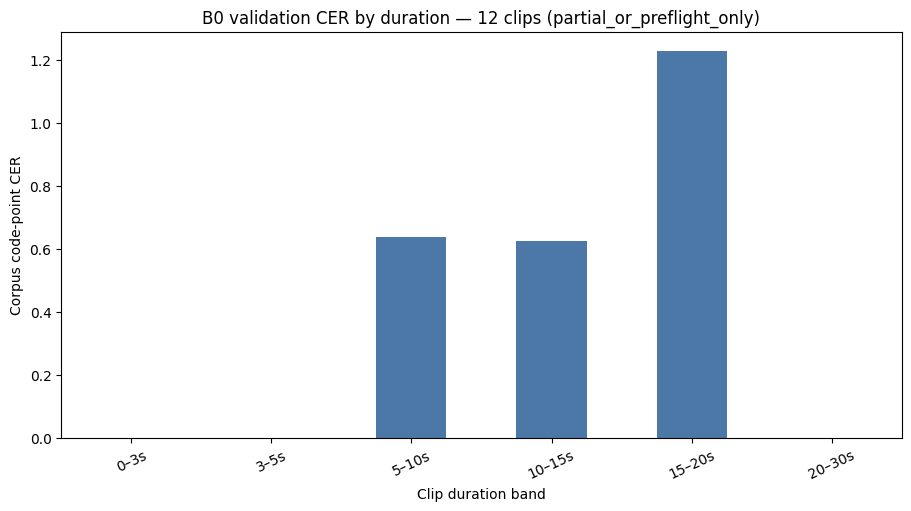

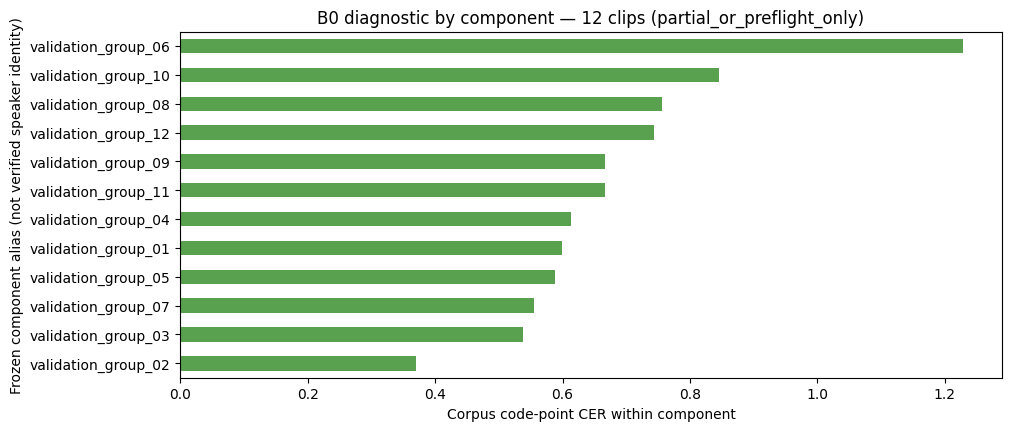

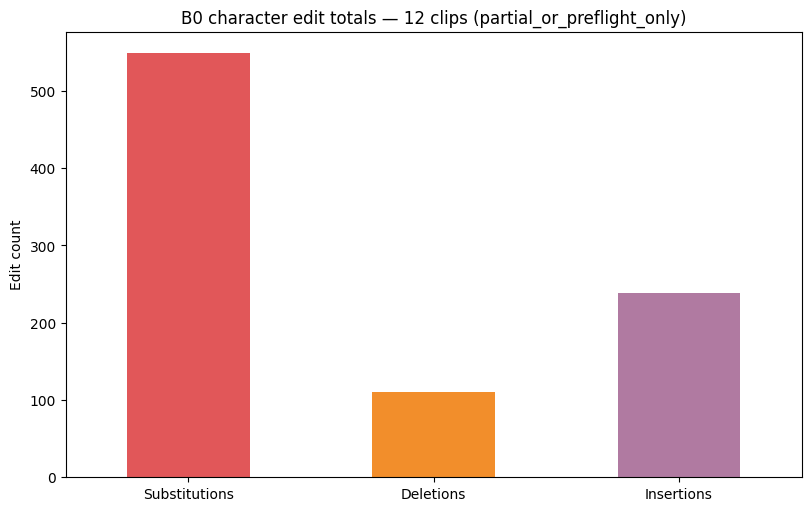

In [11]:
latest_records = load_latest_records(PREDICTIONS_JSONL)
results = pd.DataFrame(list(latest_records.values()))
if results.empty:
    raise RuntimeError("No prediction results exist yet; run the preflight cell first.")
results = results.drop_duplicates("sample_id", keep="last").copy()
results["edits"] = results["S"].astype(int) + results["D"].astype(int) + results["I"].astype(int)
results["reference_codepoints"] = results["reference_codepoints"].astype(int)
results["cer"] = np.where(
    results["reference_codepoints"] > 0,
    results["edits"] / results["reference_codepoints"],
    np.nan,
)
results["duration_seconds"] = results["duration_seconds"].astype(float)
results["status"] = results["status"].astype(str)

scored_ids = set(results["sample_id"])
all_validation_ids = set(validation["sample_id"])
pass_metrics_path = OUTPUT_DIR / "inference_passes.jsonl"
completed_passes = []
if pass_metrics_path.is_file():
    completed_passes = [json.loads(line) for line in pass_metrics_path.read_text(encoding="utf-8").splitlines() if line.strip()]
if any(item.get("run_fingerprint") != run_fingerprint for item in completed_passes):
    raise ValueError("Inference pass telemetry belongs to a different run fingerprint.")
last_pass_metrics = completed_passes[-1] if completed_passes else {}
if not scored_ids.issubset(all_validation_ids):
    raise ValueError("Prediction results contain IDs outside the frozen validation manifest.")
full_coverage = scored_ids == all_validation_ids
summary = {
    "experiment_id": "B0",
    "seed": SEED,
    "scope": "full_validation" if full_coverage else "partial_or_preflight_only",
    "status": "complete" if full_coverage else "incomplete",
    "model_id": MODEL_ID,
    "model_revision": MODEL_REVISION,
    "transformers_version": transformers.__version__,
    "torch_version": torch.__version__,
    "gpu": torch.cuda.get_device_name(0),
    "run_fingerprint": run_fingerprint,
    "validation_manifest_sha256": manifest_hash,
    "requested_validation_clips": len(validation),
    "predictions_available": int(results["sample_id"].nunique()),
    "reference_codepoints_scored": int(results["reference_codepoints"].sum()),
    "substitutions": int(results["S"].sum()),
    "deletions": int(results["D"].sum()),
    "insertions": int(results["I"].sum()),
    "edit_count": int(results["edits"].sum()),
    "corpus_cer": float(results["edits"].sum() / results["reference_codepoints"].sum()) if results["reference_codepoints"].sum() else None,
    "corpus_cer_percent": float(100 * results["edits"].sum() / results["reference_codepoints"].sum()) if results["reference_codepoints"].sum() else None,
    "decode_errors": int(results["status"].eq("decode_error").sum()),
    "empty_predictions": int(results["status"].eq("empty_prediction").sum()),
    "eos_terminated": int(results["eos_terminated"].astype(bool).sum()),
    "hit_448_token_cap_without_eos": int(results["hit_448_token_cap_without_eos"].astype(bool).sum()),
    "replacement_character_outputs": int(results["contains_replacement_character"].astype(bool).sum()),
    "mean_sample_runtime_seconds": float(results["elapsed_seconds"].astype(float).mean()),
    "summed_sample_runtime_seconds": float(results["elapsed_seconds"].astype(float).sum()),
    "evaluated_audio_hours": float(results["duration_seconds"].astype(float).sum() / 3600),
    "real_time_factor": float(results["elapsed_seconds"].astype(float).sum() / results["duration_seconds"].astype(float).sum()) if results["duration_seconds"].astype(float).sum() else None,
    "last_pass_scope": last_pass_metrics.get("scope"),
    "last_pass_newly_processed_clips": last_pass_metrics.get("newly_processed_clips"),
    "last_pass_elapsed_seconds": last_pass_metrics.get("elapsed_seconds"),
    "last_pass_peak_allocated_gpu_mib": last_pass_metrics.get("peak_allocated_gpu_bytes") / (1024 ** 2) if last_pass_metrics.get("peak_allocated_gpu_bytes") is not None else None,
    "last_pass_peak_reserved_gpu_mib": last_pass_metrics.get("peak_reserved_gpu_bytes") / (1024 ** 2) if last_pass_metrics.get("peak_reserved_gpu_bytes") is not None else None,
    "prediction_results_are_private": True,
    "test_data_used": False,
}
print(json.dumps(summary, ensure_ascii=False, indent=2))
display(results[["sample_id", "duration_seconds", "reference_codepoints", "S", "D", "I", "cer", "status"]].head(12))

# These figures are diagnostics; a 12-example preflight is not the reported full baseline.
plot_dir = OUTPUT_DIR / "plots"
plot_dir.mkdir(exist_ok=True)
plot_results = results.copy()
plot_results["duration_bin"] = pd.cut(
    plot_results["duration_seconds"],
    bins=[0, 3, 5, 10, 15, 20, 30],
    labels=["0–3s", "3–5s", "5–10s", "10–15s", "15–20s", "20–30s"],
    include_lowest=True,
    right=True,
)

def corpus_cer(group):
    denominator = int(group["reference_codepoints"].sum())
    return float(group["edits"].sum() / denominator) if denominator else np.nan

fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
cer_by_duration = pd.Series({
    label: corpus_cer(group)
    for label, group in plot_results.groupby("duration_bin", observed=False)
})
cer_by_duration.plot(kind="bar", ax=ax, color="#4c78a8")
ax.set_ylabel("Corpus code-point CER")
ax.set_xlabel("Clip duration band")
ax.set_title(f"B0 validation CER by duration — {len(results)} clips ({summary['scope']})")
ax.tick_params(axis="x", rotation=25)
fig.savefig(plot_dir / "01_cer_by_duration.png", dpi=160)
plt.show()
plt.close(fig)

component_results = pd.Series({
    component: corpus_cer(group)
    for component, group in plot_results.groupby("component_id", sort=True)
}).sort_values()
fig, ax = plt.subplots(figsize=(10, max(4, 0.35 * len(component_results))), constrained_layout=True)
component_results.plot(kind="barh", ax=ax, color="#59a14f")
ax.set_xlabel("Corpus code-point CER within component")
ax.set_ylabel("Frozen component alias (not verified speaker identity)")
ax.set_title(f"B0 diagnostic by component — {len(results)} clips ({summary['scope']})")
fig.savefig(plot_dir / "02_cer_by_component.png", dpi=160)
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
edit_totals = pd.Series({"Substitutions": int(results["S"].sum()), "Deletions": int(results["D"].sum()), "Insertions": int(results["I"].sum())})
edit_totals.plot(kind="bar", ax=ax, color=["#e15759", "#f28e2b", "#b07aa1"])
ax.set_ylabel("Edit count")
ax.set_title(f"B0 character edit totals — {len(results)} clips ({summary['scope']})")
ax.tick_params(axis="x", rotation=0)
fig.savefig(plot_dir / "03_edit_counts.png", dpi=160)
plt.show()
plt.close(fig)


## 10. Save resumable private results

This writes the scored rows, summary JSON, model/run configuration, and plots to `/kaggle/working`. The prediction table includes private sample IDs, references, and hypotheses: download and store it privately. Do not commit it or the raw Phase 5A bundle to GitHub.

In [14]:
# Recompute summary after the latest results cell and write a flat per-clip table.
latest_records = load_latest_records(PREDICTIONS_JSONL)
results = pd.DataFrame(list(latest_records.values())).drop_duplicates("sample_id", keep="last").copy()
results["edits"] = results["S"].astype(int) + results["D"].astype(int) + results["I"].astype(int)
results["reference_codepoints"] = results["reference_codepoints"].astype(int)
results["cer"] = np.where(results["reference_codepoints"] > 0, results["edits"] / results["reference_codepoints"], np.nan)
full_coverage = set(results["sample_id"]) == set(validation["sample_id"])
final_summary = {
    **summary,
    "scope": "full_validation" if full_coverage else "partial_or_preflight_only",
    "status": "complete" if full_coverage else "incomplete",
    "predictions_available": int(results["sample_id"].nunique()),
    "reference_codepoints_scored": int(results["reference_codepoints"].sum()),
    "substitutions": int(results["S"].astype(int).sum()),
    "deletions": int(results["D"].astype(int).sum()),
    "insertions": int(results["I"].astype(int).sum()),
    "edit_count": int(results["edits"].sum()),
    "corpus_cer": float(results["edits"].sum() / results["reference_codepoints"].sum()) if results["reference_codepoints"].sum() else None,
    "corpus_cer_percent": float(100 * results["edits"].sum() / results["reference_codepoints"].sum()) if results["reference_codepoints"].sum() else None,
    "decode_errors": int(results["status"].eq("decode_error").sum()),
    "empty_predictions": int(results["status"].eq("empty_prediction").sum()),
    "eos_terminated": int(results["eos_terminated"].astype(bool).sum()),
    "hit_448_token_cap_without_eos": int(results["hit_448_token_cap_without_eos"].astype(bool).sum()),
    "replacement_character_outputs": int(results["contains_replacement_character"].astype(bool).sum()),
    "summed_sample_runtime_seconds": float(results["elapsed_seconds"].astype(float).sum()),
    "evaluated_audio_hours": float(results["duration_seconds"].astype(float).sum() / 3600),
    "real_time_factor": float(results["elapsed_seconds"].astype(float).sum() / results["duration_seconds"].astype(float).sum()) if results["duration_seconds"].astype(float).sum() else None,
    "last_pass_scope": last_pass_metrics.get("scope"),
    "last_pass_newly_processed_clips": last_pass_metrics.get("newly_processed_clips"),
    "last_pass_elapsed_seconds": last_pass_metrics.get("elapsed_seconds"),
    "last_pass_peak_allocated_gpu_mib": last_pass_metrics.get("peak_allocated_gpu_bytes") / (1024 ** 2) if last_pass_metrics.get("peak_allocated_gpu_bytes") is not None else None,
    "last_pass_peak_reserved_gpu_mib": last_pass_metrics.get("peak_reserved_gpu_bytes") / (1024 ** 2) if last_pass_metrics.get("peak_reserved_gpu_bytes") is not None else None,
}
results = results.sort_values("sample_id", kind="stable").reset_index(drop=True)
results.to_csv(OUTPUT_DIR / "predictions_private.csv", index=False, encoding="utf-8")
(OUTPUT_DIR / "metrics.json").write_text(json.dumps(final_summary, ensure_ascii=False, indent=2), encoding="utf-8")
print("Saved outputs:")
for path in sorted(OUTPUT_DIR.rglob("*")):
    if path.is_file():
        print(path, f"({path.stat().st_size:,} bytes)")
print("\nFull B0 validation baseline complete:", final_summary["status"] == "complete")
print("If incomplete, retain the JSONL and rerun the inference cell to resume; do not rename or overwrite the run folder.")

# Bundle results for private download; do not upload this archive to the public repository.
import zipfile
results_zip = Path("/kaggle/working") / f"{OUTPUT_DIR.name}_results_private.zip"
with zipfile.ZipFile(results_zip, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for path in sorted(OUTPUT_DIR.rglob("*")):
        if path.is_file() and path != results_zip:
            archive.write(path, arcname=path.relative_to(OUTPUT_DIR.parent))
print("Private results archive:", results_zip, f"({results_zip.stat().st_size:,} bytes)")


Saved outputs:
/kaggle/working/phase5b_B0_119b932d396e/inference_passes.jsonl (568 bytes)
/kaggle/working/phase5b_B0_119b932d396e/metrics.json (1,409 bytes)
/kaggle/working/phase5b_B0_119b932d396e/plots/01_cer_by_duration.png (48,499 bytes)
/kaggle/working/phase5b_B0_119b932d396e/plots/02_cer_by_component.png (95,028 bytes)
/kaggle/working/phase5b_B0_119b932d396e/plots/03_edit_counts.png (33,718 bytes)
/kaggle/working/phase5b_B0_119b932d396e/predictions.jsonl (836,629 bytes)
/kaggle/working/phase5b_B0_119b932d396e/predictions_private.csv (554,891 bytes)
/kaggle/working/phase5b_B0_119b932d396e/run_config.json (5,623 bytes)

Full B0 validation baseline complete: True
If incomplete, retain the JSONL and rerun the inference cell to resume; do not rename or overwrite the run folder.
Private results archive: /kaggle/working/phase5b_B0_119b932d396e_results_private.zip (383,818 bytes)


## Phase 5B completion checklist

- [ ] Both Kaggle bundles were found by their marker files; all 737 Phase 5A payload checksums passed.
- [ ] The manifest is the frozen validation split, with 732 unique rows and 64,137 reference code points.
- [ ] The scorer's deterministic checks passed, including NFD combining marks, spaces, and empty predictions.
- [ ] The two processor figures use training-only smoke clips and show `[1, 80, 3000]` finite FP32 features plus the real-audio/padding boundary.
- [ ] Reviewed the 12-clip validation preflight; the result is labeled diagnostic only.
- [ ] Set `RUN_FULL_VALIDATION = True` and completed all 732 validation predictions, including failures in the denominator.
- [ ] Saved `metrics.json`, `predictions_private.csv`, `predictions.jsonl`, configuration, and plots from `/kaggle/working` privately.
- [ ] Test data remained unattached and unused.

**Interpretation gate:** if every listed check passes and `metrics.json` says `status: complete`, Phase 5B's B0 validation run is complete. This does not mean the model performs well; analyze the CER and errors before starting Phase 6A supervised-training smoke tests. Keep the executed Kaggle notebook and result ZIP for the project record.